In [1]:
import pandas as pd
import glob
import numpy as np
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
paths = glob.glob("../../processed_data/08_validation_oligos/*_HALO_with_SpD_info.csv")
for n in range(0,len(paths)):
    df = pd.read_csv(paths[n])
    df['sample_id'] = 'Br'+paths[n].split('Br')[1].split('_HALO')[0]
    if n == 0:
        all_df = df
    else:
        all_df = pd.concat([all_df, df], axis = 0)
np.shape(all_df)

(925882, 40)

In [19]:
all_df = all_df[(all_df['DAPI_DAPI_Positive']==1)]

GM = all_df[(all_df['SpD']!=0)]

In [22]:
grouped = GM[['MBP_Opal520_PositiveNucleus', 'DAPI_DAPI_PositiveNucleus', 'SWM', 'sample_id']].groupby(['SWM','sample_id']).sum()
grouped['% MBP+'] = grouped['MBP_Opal520_PositiveNucleus']/grouped['DAPI_DAPI_PositiveNucleus']*100
grouped

In [37]:
map_sample_type = {
    'Br2934': 'PD',  
    'Br5347': 'Control',  
    'Br5785': 'Control',  
    'Br5766': 'PD',  
    'Br5394': 'PD',  
    'Br9413': 'Control',  
}

grouped['group'] = grouped.reset_index('SWM').index.map(map_sample_type)

In [38]:
grouped

MBP_Opal520_PositiveNucleus  DAPI_DAPI_PositiveNucleus  \
SWM sample_id                                                           
0   Br2934                            2646                      23255   
    Br5347                            6440                      81825   
    Br5394                            8265                      77770   
    Br5766                            1180                      67202   
    Br5785                           12257                      62182   
    Br9413                            1982                      42161   

                  % MBP+    group  
SWM sample_id                      
0   Br2934     11.378198       PD  
    Br5347      7.870455  Control  
    Br5394     10.627491       PD  
    Br5766      1.755900       PD  
    Br5785     19.711492  Control  
    Br9413      4.701027  Control

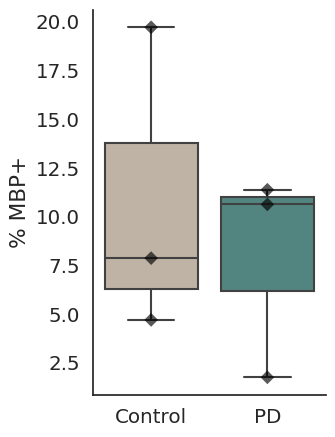

In [42]:
from pylab import rcParams
rcParams['figure.figsize'] = 3,5
sns.set(font_scale=1.3, style = "white")
#sns.set_theme("whitegrid")

custom_palette = {
    'PD': '#4B8D86',  
    'Control': '#C3B3A1',  
}
custom_order = ['Control', 'PD']

sns.boxplot(x = grouped['group'], y = grouped['% MBP+'], palette = custom_palette, order=custom_order)
sns.swarmplot(x = grouped['group'], y = grouped['% MBP+'], color = 'black', marker="D", size = 7, alpha=.65, order=custom_order)
sns.despine(right=True)
plt.xlabel('')
#plt.savefig('../../plots/08_validation_oligos/rnascope_total_OGs_group.pdf', dpi = 300, bbox_inches = 'tight')
#plt.savefig('../../plots/08_validation_oligos/rnascope_total_OGs_group.png', dpi = 300, bbox_inches = 'tight')
plt.show()

In [41]:
grouped

MBP_Opal520_PositiveNucleus  DAPI_DAPI_PositiveNucleus  \
SWM sample_id                                                           
0   Br2934                            2646                      23255   
    Br5347                            6440                      81825   
    Br5394                            8265                      77770   
    Br5766                            1180                      67202   
    Br5785                           12257                      62182   
    Br9413                            1982                      42161   

                  % MBP+    group  
SWM sample_id                      
0   Br2934     11.378198       PD  
    Br5347      7.870455  Control  
    Br5394     10.627491       PD  
    Br5766      1.755900       PD  
    Br5785     19.711492  Control  
    Br9413      4.701027  Control

## Oligo counts

In [4]:
grouped = all_df[['MBP_Opal520_PositiveNucleus', 'DAPI_DAPI_PositiveNucleus', 'SpD', 'sample_id']].groupby(['SpD','sample_id']).sum()

In [18]:
all_df['SpD'].unique()

array([0, 3, 1, 2, 4])

In [39]:
grouped['% MBP+'] = grouped['MBP_Opal520_PositiveNucleus']/grouped['DAPI_DAPI_PositiveNucleus']*100

In [40]:
piv = pd.pivot_table(grouped, values=['% MBP+'], index=['sample_id'], columns = ['SpD'])
piv.columns

MultiIndex([('% MBP+', 0),
            ('% MBP+', 1),
            ('% MBP+', 2),
            ('% MBP+', 3),
            ('% MBP+', 4)],
           names=[None, 'SpD'])

In [41]:
piv['SpD1'] = piv['% MBP+', 1]#/piv['% MBP+', 0]
piv['SpD2'] = piv['% MBP+', 2]#/piv['% MBP+', 0]
piv['SpD3'] = piv['% MBP+', 3]#/piv['% MBP+', 0]
piv['SpD4'] = piv['% MBP+', 4]#/piv['% MBP+', 0]
piv['WM'] = piv['% MBP+', 0]#/piv['% MBP+', 0]

In [42]:
sub = piv[['SpD1','SpD2','SpD3','SpD4','WM']]

In [43]:
plotting_df = pd.DataFrame(data=sub.values.T, columns = ['Br2934', 'Br5347', 'Br5394', 'Br5766', 'Br5785', 'Br9413'], index = ['SpD1','SpD2','SpD3','SpD4','WM'])

In [44]:
plotting_df.index.name = 'sample_id'

In [45]:
df_reset = plotting_df.reset_index()
df_melted = pd.melt(df_reset, id_vars='sample_id', var_name='SpD', value_name='value')

In [46]:
df_melted = df_melted.rename(columns={'sample_id':'SpD','SpD':'sample_id'})

In [47]:
# Define your PD sample IDs
pd_samples = ['Br2934', 'Br5394', 'Br5766']

# Create the new column
df_melted['Group'] = np.where(df_melted['sample_id'].isin(pd_samples), 'PD', 'Control')

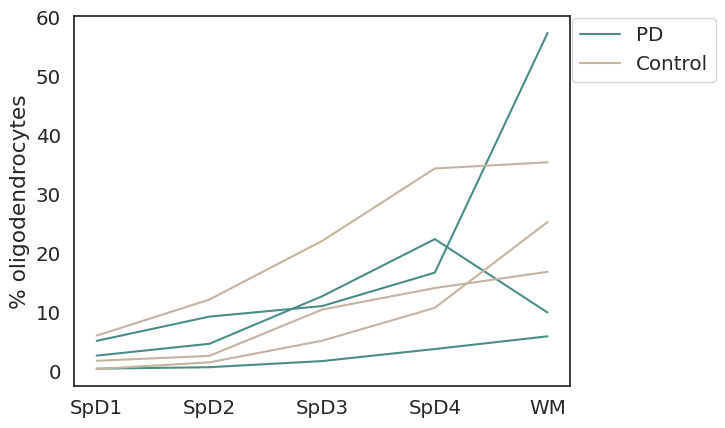

In [48]:
import matplotlib.pyplot as plt 
sns.set(font_scale = 1.3, style = "white")

sns.lineplot(data = df_melted, x = 'SpD', y = 'value', hue = 'Group', units = 'sample_id', estimator = None,  palette={"PD": "#4B8D86", "Control":"#C3B3A1"})
plt.ylabel('% oligodendrocytes')
plt.xlabel('')
plt.legend(bbox_to_anchor=(1, 1), loc='upper left', borderaxespad=0.1)
plt.savefig('../../plots/08_validation_oligos/RNAscope_outputs.png', dpi = 300, bbox_inches = 'tight')
plt.show()

In [32]:
import scipy.stats as stats

In [59]:
stats.levene(df_melted[df_melted['SpD']=='SpD1']['value'], df_melted[df_melted['SpD']=='WM']['value'], center='mean')

LeveneResult(statistic=7.5317563791344515, pvalue=0.02067585416290936)

In [60]:
PD_res = stats.levene(PD['SpD1'], PD['WM'], center='mean')

In [61]:
Ctrl_res = stats.levene(Control['SpD1'], Control['WM'], center='mean')

In [67]:
All_res = [PD_res.pvalue, Ctrl_res.pvalue]

In [68]:
All_res

[0.02286826357324292, 0.23616136417886238]

In [70]:
import statsmodels.stats.multitest as sm 

sm.fdrcorrection(All_res, alpha=0.05, method='indep', is_sorted=False)[1]


array([0.04573653, 0.23616136])

In [203]:
stats.levene(PD['SpD1'], Control['SpD1'], center='mean')


LeveneResult(statistic=0.34975801893816794, pvalue=0.5860543060087811)

In [204]:
stats.levene(PD['SpD2'], Control['SpD2'], center='mean')

LeveneResult(statistic=0.7554025387200116, pvalue=0.4338134806384953)

In [205]:
stats.levene(PD['SpD3'], Control['SpD3'], center='mean')

LeveneResult(statistic=0.5278840009561033, pvalue=0.5077352477327363)

In [206]:
stats.levene(PD['SpD4'], Control['SpD4'], center='mean')

LeveneResult(statistic=0.5914564244296079, pvalue=0.4847511138236224)

In [318]:
stats.levene(PD['WM'], Control['WM'], center='mean')


LeveneResult(statistic=6.074966461822849, pvalue=0.06933697073261424)

## MBP intensity

In [175]:
grouped = all_df[['MBP_Opal520_NucleusIntensity', 'DAPI_DAPI_NucleusIntensity', 'SpD', 'sample_id']].groupby(['SpD','sample_id']).sum()


In [176]:
piv = pd.pivot_table(grouped, values=['MBP_Opal520_NucleusIntensity'], index=['sample_id'], columns = ['SpD'])

In [177]:
piv['SpD1/WM'] = piv['MBP_Opal520_NucleusIntensity', 1]/piv['MBP_Opal520_NucleusIntensity', 0]
piv['SpD2/WM'] = piv['MBP_Opal520_NucleusIntensity', 2]/piv['MBP_Opal520_NucleusIntensity', 0]
piv['SpD3/WM'] = piv['MBP_Opal520_NucleusIntensity', 3]/piv['MBP_Opal520_NucleusIntensity', 0]
piv['SpD4/WM'] = piv['MBP_Opal520_NucleusIntensity', 4]/piv['MBP_Opal520_NucleusIntensity', 0]
piv['WM/WM'] = piv['MBP_Opal520_NucleusIntensity', 0]/piv['MBP_Opal520_NucleusIntensity', 0]

In [53]:
piv['Group'] = ['PD','Control','PD','PD','Control', 'Control']

PD = piv[piv['Group'] == 'PD']
Control = piv[piv['Group'] == 'Control']

In [179]:
stats.levene(PD['SpD1/WM'], Control['SpD1/WM'], center='mean')

LeveneResult(statistic=0.04425995029532507, pvalue=0.8436528384850157)

In [180]:
stats.levene(PD['SpD2/WM'], Control['SpD2/WM'], center='mean')

LeveneResult(statistic=5.300041132670705, pvalue=0.08274024252097581)

In [181]:
stats.levene(PD['SpD3/WM'], Control['SpD3/WM'], center='mean')

LeveneResult(statistic=4.511143104997351, pvalue=0.10089293164930574)

In [182]:
stats.levene(PD['SpD4/WM'], Control['SpD4/WM'], center='mean')#


LeveneResult(statistic=3.3902768670027585, pvalue=0.13939291506688598)